# An 18 MW alkaline electrolysis plant: paper audit and NeqSim evaluation

**Version 1.0.0 · 28 October 2026 · companion to [NeqSim #4651](https://github.com/equinor/neqsim/issues/4651).**

Can NeqSim support the industrial study in Al-Hebshi et al., *Simulation of an 18 MW
Alkaline Electrolysis Plant for Green Hydrogen Production in Abu Dhabi* (2024)?
This notebook audits the reported numbers, runs the native alkaline `Electrolyzer`,
and connects its products to cooling and two-stage hydrogen compression in a reusable
`ProcessSystem`. It compares power and production over a bounded operating range.

**Finding:** the paper's 3,753 kg/h at 18 MW implies 4.80 kWh/kg, which cannot be used
as a credible electricity-only validation target. A transparent screening case is feasible
in NeqSim, but reproducing the paper's KOH process or validating a real plant is not established.

Learning outcomes: audit source units and boundaries; distinguish Faradaic and energy
efficiency; use current NeqSim master with provenance; check Faraday's law, material
balances and compressor energy; interpret limitations before proposing further research.

Source: [publisher article](https://ijoir.gov.iq/ijoir/index.php/jou/article/view/471),
[publisher PDF](https://ijoir.gov.iq/ijoir/index.php/jou/article/download/471/226),
[DOI 10.53523/ijoirVol11I3ID471](https://doi.org/10.53523/ijoirVol11I3ID471).
The paper is a conceptual Aspen Plus simulation, with no experimental validation dataset.
Only a few attributed numeric inputs are transcribed; derived checks are calculated here.

In [1]:
import importlib.metadata as metadata
import os
from pathlib import Path
import subprocess
import sys

required = {'neqsim': '3.26.0'}
missing = []
for package, version in required.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f'{package}=={version}')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
for package in ['numpy', 'pandas', 'matplotlib']:
    try:
        metadata.version(package)
    except metadata.PackageNotFoundError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
print('Python:', sys.version.split()[0])
for package in ['neqsim', 'jpype1', 'numpy', 'pandas', 'matplotlib']:
    print(f'{package}: {metadata.version(package)}')

Python: 3.12.14
neqsim: 3.26.0
jpype1: 1.7.1
numpy: 2.5.4
pandas: 3.1.0
matplotlib: 3.11.2


## 1. Source-built NeqSim runtime

The Python package supplies the bridge. The Java physics is built from the immutable
master commit inspected for this study. A clean Linux Colab runtime needs Java 17 and
Maven; this cell installs them if missing, builds the JAR, and verifies its loaded location.
A local validated build may be supplied through `NEQSIM_SOURCE_ROOT` and
`NEQSIM_SOURCE_JAR`; the commit and class-location assertions still apply.
Restart the runtime before rerunning with a different JAR.

In [2]:
import hashlib
import shutil
import jpype

NEQSIM_SOURCE_REF = 'f8a83ed106ea3ab08909d809bd3f7f8b4ffa7748'
source_root = Path(os.environ.get('NEQSIM_SOURCE_ROOT', '/tmp/neqsim_4651_source'))
if not (source_root / '.git').exists():
    subprocess.check_call([
        'git', 'clone', '--filter=blob:none', '--no-checkout',
        'https://github.com/equinor/neqsim.git', str(source_root),
    ])
    subprocess.check_call(['git', 'checkout', '--detach', NEQSIM_SOURCE_REF], cwd=source_root)
resolved_commit = subprocess.check_output(
    ['git', 'rev-parse', 'HEAD'], cwd=source_root, text=True,
).strip()
assert resolved_commit == NEQSIM_SOURCE_REF, resolved_commit
jar_override = os.environ.get('NEQSIM_SOURCE_JAR')
source_jar = Path(jar_override) if jar_override else source_root / 'target/neqsim-3.26.0.jar'
if not source_jar.exists():
    if shutil.which('java') is None or shutil.which('mvn') is None:
        subprocess.check_call(['apt-get', '-qq', 'update'])
        subprocess.check_call([
            'apt-get', '-qq', 'install', '-y', 'openjdk-17-jdk-headless', 'maven',
        ])
    subprocess.check_call([
        'mvn', '-q', '-DskipTests', '-Dmaven.javadoc.skip=true', 'package',
    ], cwd=source_root)
source_jar = source_jar.resolve()
assert not jpype.isJVMStarted(), 'Restart this runtime to change the source-built JAR.'
os.environ['NEQSIM_JVM_AUTOSTART'] = '0'
jpype.addClassPath(str(source_jar))
jpype.startJVM(convertStrings=True)
Electrolyzer = jpype.JClass('neqsim.process.equipment.electrolyzer.Electrolyzer')
Technology = jpype.JClass('neqsim.process.equipment.electrolyzer.ElectrolyzerTechnology')
IVModel = jpype.JClass('neqsim.process.equipment.electrolyzer.ElectrolyzerIVCharacteristic')
for java_class in [Electrolyzer, IVModel]:
    location = str(java_class.class_.getProtectionDomain().getCodeSource().getLocation())
    assert source_jar.as_uri() == location or str(source_jar) in location, location
print('NeqSim master source:', resolved_commit)
print('JAR SHA-256:', hashlib.sha256(source_jar.read_bytes()).hexdigest())
print('Loaded Electrolyzer and IV model from:', source_jar.name)
print('Java:', jpype.JClass('java.lang.System').getProperty('java.version'))

NeqSim master source: f8a83ed106ea3ab08909d809bd3f7f8b4ffa7748
JAR SHA-256: fa371c7285f2aa3404f5e369797fc63e50cee83e62cdc1f97e992dccdba9d4bb
Loaded Electrolyzer and IV model from: neqsim-3.26.0.jar
Java: 17.0.20


## 2. Audit the paper before calibration

Page 5, Table 7 reports the three rates below; page 2 gives the 18 MW rating.
Page 4, Table 6 labels the separator pressure **7 barg**, converted here to
8.01325 bara with atmospheric pressure 1.01325 bar. The paper does not state a cell
voltage, current density, Faradaic efficiency, stack temperature or a complete energy boundary.
Its KOH concentration and gas-purity bases are also unclear.

For an independent **25 °C, 1 bar, liquid-water reference**, NIST formation enthalpy
and standard entropies give the reversible electrical work. This is not the exact
limit at the unknown stack conditions; substantial external exergy could change the
boundary. No such source is documented in the paper.

$$\Delta G^\circ=\Delta H^\circ-T\left(S_{H_2}^\circ+\tfrac{1}{2}S_{O_2}^\circ-S_{H_2O}^\circ\right)$$

Here $\Delta H^\circ=285.830$ kJ/mol for water splitting, $T=298.15$ K, and $S^\circ$
is standard molar entropy in J/(mol K).

$$\mathrm{SEC}_{rev}=\frac{\Delta G^\circ}{3600M_{H_2}}$$

SEC is kWh/kg when $\Delta G^\circ$ is kJ/mol and $M_{H_2}$ is kg/mol.
Constants: [NIST H₂](https://webbook.nist.gov/cgi/cbook.cgi?Name=H2&cTG=on),
[NIST O₂](https://webbook.nist.gov/cgi/cbook.cgi?ID=C7782447&Mask=1),
[NIST water](https://webbook.nist.gov/cgi/cbook.cgi?Name=water&cTC=on).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 110)
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10})
FARADAY = 96485.3329
R_GAS = 8.314462618
MW_H2 = 0.00201588
MW_O2 = 0.0319988
MW_WATER = 0.01801528
paper = {
    'power_kW': 18000.0,
    'hydrogen_kg_h': 3753.0,
    'oxygen_kg_h': 28906.0,
    'makeup_water_kg_h': 35666.5,
}
reference_temperature_K = 298.15
delta_entropy_J_mol_K = 130.680 + 0.5 * 205.152 - 69.95
delta_g_kJ_mol = 285.830 - reference_temperature_K * delta_entropy_J_mol_K / 1000.0
reversible_sec = delta_g_kJ_mol / (3600.0 * MW_H2)
paper_sec = paper['power_kW'] / paper['hydrogen_kg_h']
stoich_oxygen = paper['hydrogen_kg_h'] * MW_O2 / (2.0 * MW_H2)
stoich_water = paper['hydrogen_kg_h'] * MW_WATER / MW_H2
audit = pd.DataFrame([
    ['Reported electricity / H2', paper_sec, 'kWh/kg'],
    ['25 C reversible reference', reversible_sec, 'kWh/kg'],
    ['18 MW reversible reference ceiling', 18000.0 / reversible_sec, 'kg H2/h'],
    ['50 kWh/kg illustrative production', 18000.0 / 50.0, 'kg H2/h'],
    ['Stoichiometric O2 at claimed H2 rate', stoich_oxygen, 'kg/h'],
    ['Reported O2 relative discrepancy', 100.0 * (paper['oxygen_kg_h'] / stoich_oxygen - 1), '%'],
    ['Stoichiometric water at claimed H2 rate', stoich_water, 'kg/h'],
], columns=['Audit quantity', 'Value', 'Unit'])
display(audit.round(4))
print(f'Claimed rate / reversible reference ceiling: {reversible_sec / paper_sec:.3f}')
print('O2 and makeup-water discrepancies require clarified product and purge bases.')

Claimed rate / reversible reference ceiling: 6.813
O2 and makeup-water discrepancies require clarified product and purge bases.


,Audit quantity,Value,Unit
0,Reported electricity / H2,4.7962,kWh/kg
1,25 C reversible reference,32.6767,kWh/kg
2,18 MW reversible reference ceiling,550.8512,kg H2/h
3,50 kWh/kg illustrative production,360.0000,kg H2/h
4,Stoichiometric O2 at claimed H2 rate,29786.3703,kg/h
5,Reported O2 relative discrepancy,-2.9556,%
6,Stoichiometric water at claimed H2 rate,33539.3703,kg/h


## 3. Explicit screening assumptions and composable process

Use the paper's 7 barg pressure but **assume** an 80 °C stack, 1.85 V per cell,
unity Faradaic efficiency, 97% rectifier efficiency and auxiliaries equal to 2% of DC
stack power. Interpret 18 MW as an AC budget excluding export compression. These are
educational inputs, not values reconstructed or fitted from the paper. The DC stack
rating is 18 MW. No 20,000-cell topology is inferred because active area and wiring are absent.

$$\dot n_{H_2}=\frac{\eta_F I_{eq}}{2F},\qquad P_{DC}=V_{cell}I_{eq},\qquad P_{AC}=P_{DC}\left(\frac{1}{\eta_{rect}}+f_{aux}\right)$$

$I_{eq}$ is the summed cell-current equivalent in A, not a terminal current for a
specified series stack; $F$ is C/mol, $V_{cell}$ is V, and powers are W.
Faradaic efficiency $\eta_F$ measures charge utilization; energy losses also depend on voltage.
Unity $\eta_F$ avoids the current native nonunity-efficiency balance defect audited below.

`Electrolyzer` supplies pure dry H₂/O₂ streams using its native `Fluid` factory;
the feed is pure-water SRK. The gas factory's model is printed below. No electrolyte or
wet-gas purification is implied. Cool dry H₂ to 35 °C, compress in two equal pressure-ratio
stages to an **assumed 100 bara**, with 75% isentropic efficiency, 95% motor efficiency and 35 °C intercooling.
Neglect pipe and cooler pressure losses. Cool oxygen separately. All units share one
`ProcessSystem`; named objects remain available for larger studies.

In [4]:
SystemSrkEos = jpype.JClass('neqsim.thermo.system.SystemSrkEos')
Stream = jpype.JClass('neqsim.process.equipment.stream.Stream')
Cooler = jpype.JClass('neqsim.process.equipment.heatexchanger.Cooler')
Compressor = jpype.JClass('neqsim.process.equipment.compressor.Compressor')
ProcessSystem = jpype.JClass('neqsim.process.processmodel.ProcessSystem')

STACK_PRESSURE_BARA = 7.0 + 1.01325
STACK_TEMPERATURE_K = 353.15
COOLING_TEMPERATURE_K = 308.15
CELL_VOLTAGE = 1.85
RECTIFIER_EFFICIENCY = 0.97
AUXILIARY_FRACTION = 0.02
MOTOR_EFFICIENCY = 0.95

def build_case(power_MW=18.0, delivery_bara=100.0, voltage=CELL_VOLTAGE):
    water_fluid = SystemSrkEos(STACK_TEMPERATURE_K, STACK_PRESSURE_BARA)
    water_fluid.addComponent('water', 1.0)
    water_fluid.setMixingRule(2)
    water = Stream('preheated demineralized water', water_fluid)
    water.setFlowRate(1.0, 'kg/hr')
    stack = Electrolyzer('alkaline stack', water)
    stack.setTechnology(Technology.ALKALINE)
    stack.setCellVoltage(voltage)
    stack.setFaradaicEfficiency(1.0)
    stack.setRectifierEfficiency(RECTIFIER_EFFICIENCY)
    stack.setAuxiliaryLoadFraction(AUXILIARY_FRACTION)
    stack.sizeStack(18.0e6)
    stack.setAvailablePower(power_MW * 1.0e6)
    h2_cooler = Cooler('hydrogen precooler', stack.getHydrogenOutStream())
    h2_cooler.setOutTemperature(COOLING_TEMPERATURE_K)
    process = ProcessSystem()
    process.add(water)
    process.add(stack)
    process.add(h2_cooler)
    compressors = []
    gas_coolers = [h2_cooler]
    inlet = h2_cooler.getOutletStream()
    for stage in [1, 2]:
        pressure = STACK_PRESSURE_BARA * (delivery_bara / STACK_PRESSURE_BARA) ** (stage / 2)
        compressor = Compressor(f'hydrogen compressor {stage}', inlet)
        compressor.setOutletPressure(pressure)
        compressor.setIsentropicEfficiency(0.75)
        cooler = Cooler(f'hydrogen stage {stage} cooler', compressor.getOutletStream())
        cooler.setOutTemperature(COOLING_TEMPERATURE_K)
        process.add(compressor)
        process.add(cooler)
        compressors.append(compressor)
        gas_coolers.append(cooler)
        inlet = cooler.getOutletStream()
    oxygen_cooler = Cooler('oxygen cooler', stack.getOxygenOutStream())
    oxygen_cooler.setOutTemperature(COOLING_TEMPERATURE_K)
    process.add(oxygen_cooler)
    return {
        'process': process, 'water': water, 'stack': stack,
        'compressors': compressors, 'gas_coolers': gas_coolers,
        'oxygen_cooler': oxygen_cooler, 'hydrogen_export': inlet,
        'oxygen_export': oxygen_cooler.getOutletStream(),
    }

base = build_case()
base['process'].run()
print('Native product fluid model:', base['hydrogen_export'].getFluid().getModelName())
print('Process units:', base['process'].getUnitOperations().size())
print('Native IV characteristic is available; no uncalibrated IV curve is fitted here.')

Native product fluid model: SRK-EOS
Process units: 8
Native IV characteristic is available; no uncalibrated IV curve is fitted here.


In [5]:
def summarize_case(case):
    stack = case['stack']
    h2_rate = case['hydrogen_export'].getFlowRate('kg/hr')
    compression_W = sum(unit.getPower() for unit in case['compressors'])
    ac_power_W = stack.getSystemPower()
    return {
        'H2 kg/h': h2_rate,
        'O2 kg/h': case['oxygen_export'].getFlowRate('kg/hr'),
        'Water kg/h': case['water'].getFlowRate('kg/hr'),
        'Stack DC MW': stack.getStackPower() / 1e6,
        'Stack system AC MW': ac_power_W / 1e6,
        'Compression shaft MW': compression_W / 1e6,
        'Compression AC MW': compression_W / MOTOR_EFFICIENCY / 1e6,
        'Total electrical MW': (ac_power_W + compression_W / MOTOR_EFFICIENCY) / 1e6,
        'AC SEC kWh/kg': ac_power_W / (1000.0 * h2_rate),
        'Export SEC kWh/kg': (ac_power_W + compression_W / MOTOR_EFFICIENCY) / (1000.0 * h2_rate),
        'Native stack heat MW': stack.getWasteHeat() / 1e6,
    }

base_results = summarize_case(base)
display(pd.DataFrame.from_dict(base_results, orient='index', columns=['Value']).round(5))
stream_rows = []
for label, stream in [
    ('Stack H2', base['stack'].getHydrogenOutStream()),
    ('Precooler H2', base['gas_coolers'][0].getOutletStream()),
    ('Compressor 1 H2', base['compressors'][0].getOutletStream()),
    ('Intercooled H2', base['gas_coolers'][1].getOutletStream()),
    ('Compressor 2 H2', base['compressors'][1].getOutletStream()),
    ('Export H2', base['hydrogen_export']),
]:
    stream_rows.append([
        label, stream.getPressure('bara'), stream.getTemperature('C'),
        stream.getFlowRate('kg/hr'),
    ])
display(pd.DataFrame(stream_rows, columns=['Stream', 'bara', 'C', 'kg/h']).round(4))

,Value
H2 kg/h,348.20068
O2 kg/h,2763.41110
Water kg/h,3111.52542
Stack DC MW,17.12772
Stack system AC MW,18.00000
Compression shaft MW,0.50742
Compression AC MW,0.53413
Total electrical MW,18.53413
AC SEC kWh/kg,51.69433
Export SEC kWh/kg,53.22829


,Stream,bara,C,kg/h
0,Stack H2,8.0132,80.0000,348.2007
1,Precooler H2,8.0132,35.0000,348.2007
2,Compressor 1 H2,28.3077,213.9627,348.2007
3,Intercooled H2,28.3077,35.0000,348.2007
4,Compressor 2 H2,100.0000,214.9532,348.2007
5,Export H2,100.0000,35.0000,348.2007


## 4. Validation and boundary checks

Check molar H/O conservation, total mass, the AC/DC conversion, Faraday's law,
compressor enthalpy/work and cooler enthalpy/duty. The native species database has
rounded molar masses, so mass tolerance is 0.01%; molar stoichiometry is checked more tightly.
The ideal-gas isothermal work $\dot nRT\ln(p_2/p_1)$ at 35 °C is a reference lower bound
for this dry-gas compression train, not an independent high-pressure EOS benchmark.

The native stack heat is a simplified thermoneutral-voltage estimate. It is **not**
a full energy balance including feed preheating, KOH loops, sensible reaction enthalpy
and ambient heat exchange. Energy validation here covers the explicit gas equipment
and the electrical/Faraday relations; no total-plant thermal closure is claimed.

In [6]:
stack = base['stack']
water_mol_s = base['water'].getFlowRate('mole/sec')
h2_mol_s = stack.getHydrogenOutStream().getFlowRate('mole/sec')
o2_mol_s = stack.getOxygenOutStream().getFlowRate('mole/sec')
input_mass = base['water'].getFlowRate('kg/hr')
output_mass = base_results['H2 kg/h'] + base_results['O2 kg/h']
predicted_h2 = stack.getStackPower() / (CELL_VOLTAGE * 2.0 * FARADAY)
expected_dc = 18e6 / (1.0 / RECTIFIER_EFFICIENCY + AUXILIARY_FRACTION)
compression_W = sum(unit.getPower() for unit in base['compressors'])
isothermal_W = h2_mol_s * R_GAS * COOLING_TEMPERATURE_K * np.log(100 / STACK_PRESSURE_BARA)
checks = []

def check(label, residual, tolerance):
    assert np.isfinite(residual)
    passed = abs(residual) <= tolerance
    checks.append([label, residual, tolerance, passed])
    assert passed, (label, residual, tolerance)

check('H atom relative closure', h2_mol_s / water_mol_s - 1, 1e-8)
check('O atom relative closure', 2.0 * o2_mol_s / water_mol_s - 1, 1e-8)
check('Mass relative closure', output_mass / input_mass - 1, 1e-4)
check('Faraday relative error', h2_mol_s / predicted_h2 - 1, 1e-8)
check('AC/DC relative error', stack.getStackPower() / expected_dc - 1, 1e-8)
check('AC budget relative error', stack.getSystemPower() / 18e6 - 1, 1e-8)
for index, unit in enumerate(base['compressors'], start=1):
    delta_h = unit.getOutletStream().getFluid().getEnthalpy()
    delta_h -= unit.getInletStream().getFluid().getEnthalpy()
    check(f'Compressor {index} energy relative error', delta_h / unit.getPower() - 1, 1e-7)
    assert unit.getOutletStream().getTemperature('K') > unit.getInletStream().getTemperature('K')
for index, unit in enumerate(base['gas_coolers'] + [base['oxygen_cooler']], start=1):
    delta_h = unit.getOutletStream().getFluid().getEnthalpy()
    delta_h -= unit.getInletStream().getFluid().getEnthalpy()
    check(f'Cooler {index} energy relative error', (delta_h - unit.getDuty()) / 1e6, 1e-8)
check('Export pressure relative error', base['hydrogen_export'].getPressure('bara') / 100 - 1, 1e-9)
assert compression_W > isothermal_W > 0.0
before_repeat = base_results['H2 kg/h']
base['process'].run()
check('Repeat H2 relative difference', summarize_case(base)['H2 kg/h'] / before_repeat - 1, 1e-9)
display(pd.DataFrame(checks, columns=['Check', 'Residual', 'Tolerance', 'Pass']))
print(f'Compression shaft power: {compression_W / 1000:.3f} kW')
print(f'Ideal isothermal reference: {isothermal_W / 1000:.3f} kW')
print(f'{len(checks)} quantitative checks passed; compressor temperatures and work bound passed.')

Compression shaft power: 507.421 kW
Ideal isothermal reference: 310.267 kW
14 quantitative checks passed; compressor temperatures and work bound passed.


,Check,Residual,Tolerance,Pass
0,H atom relative closure,0.000000,1.000000e-08,True
1,O atom relative closure,0.000000,1.000000e-08,True
2,Mass relative closure,0.000028,1.000000e-04,True
3,Faraday relative error,0.000000,1.000000e-08,True
4,AC/DC relative error,0.000000,1.000000e-08,True
5,AC budget relative error,0.000000,1.000000e-08,True
6,Compressor 1 energy relative error,0.000000,1.000000e-07,True
7,Compressor 2 energy relative error,0.000000,1.000000e-07,True
8,Cooler 1 energy relative error,0.000000,1.000000e-08,True
9,Cooler 2 energy relative error,0.000000,1.000000e-08,True


## 5. Compare useful outputs and nearby operating points

The source paper rate is shown as an audited claim, not a target passed by the model.
The load sweep retains constant assumed cell voltage and efficiencies; therefore its
linear production trend is imposed by this screening model, not a prediction of real
part-load electrochemistry. Voltage and delivery-pressure sweeps show which missing
inputs affect the answer. The native IV model could replace the fixed voltage after
calibration against independent cell data.

In [7]:
load_rows = []
for power_MW in [4.5, 9.0, 13.5, 18.0]:
    case = build_case(power_MW=power_MW)
    case['process'].run()
    values = summarize_case(case)
    load_rows.append([
        power_MW, values['H2 kg/h'], values['Compression shaft MW'],
        values['Export SEC kWh/kg'],
    ])
loads = pd.DataFrame(load_rows, columns=[
    'AC MW', 'H2 kg/h', 'Compression shaft MW', 'Export SEC kWh/kg',
])
assert np.all(np.diff(loads['H2 kg/h']) > 0)
assert np.ptp(loads['H2 kg/h'] / loads['AC MW']) < 1e-5
voltage_rows = []
for voltage in [1.7, 1.85, 2.0, 2.2]:
    case = build_case(voltage=voltage)
    case['process'].run()
    voltage_rows.append([voltage, summarize_case(case)['H2 kg/h']])
voltages = pd.DataFrame(voltage_rows, columns=['Cell V', 'H2 kg/h'])
assert np.all(np.diff(voltages['H2 kg/h']) < 0)
pressure_rows = []
for pressure in [30.0, 60.0, 100.0]:
    case = build_case(delivery_bara=pressure)
    case['process'].run()
    values = summarize_case(case)
    pressure_rows.append([pressure, values['Compression shaft MW'], values['Export SEC kWh/kg']])
pressures = pd.DataFrame(pressure_rows, columns=[
    'Delivery bara', 'Compression shaft MW', 'Export SEC kWh/kg',
])
assert np.all(np.diff(pressures['Compression shaft MW']) > 0)
display(loads.round(4))
display(voltages.round(4))
display(pressures.round(4))

,AC MW,H2 kg/h,Compression shaft MW,Export SEC kWh/kg
0,4.5,87.0502,0.1269,53.2283
1,9.0,174.1003,0.2537,53.2283
2,13.5,261.1505,0.3806,53.2283
3,18.0,348.2007,0.5074,53.2283


,Cell V,H2 kg/h
0,1.70,378.9243
1,1.85,348.2007
2,2.00,322.0856
3,2.20,292.8051


,Delivery bara,Compression shaft MW,Export SEC kWh/kg
0,30.0,0.2403,52.4206
1,60.0,0.3875,52.8658
2,100.0,0.5074,53.2283


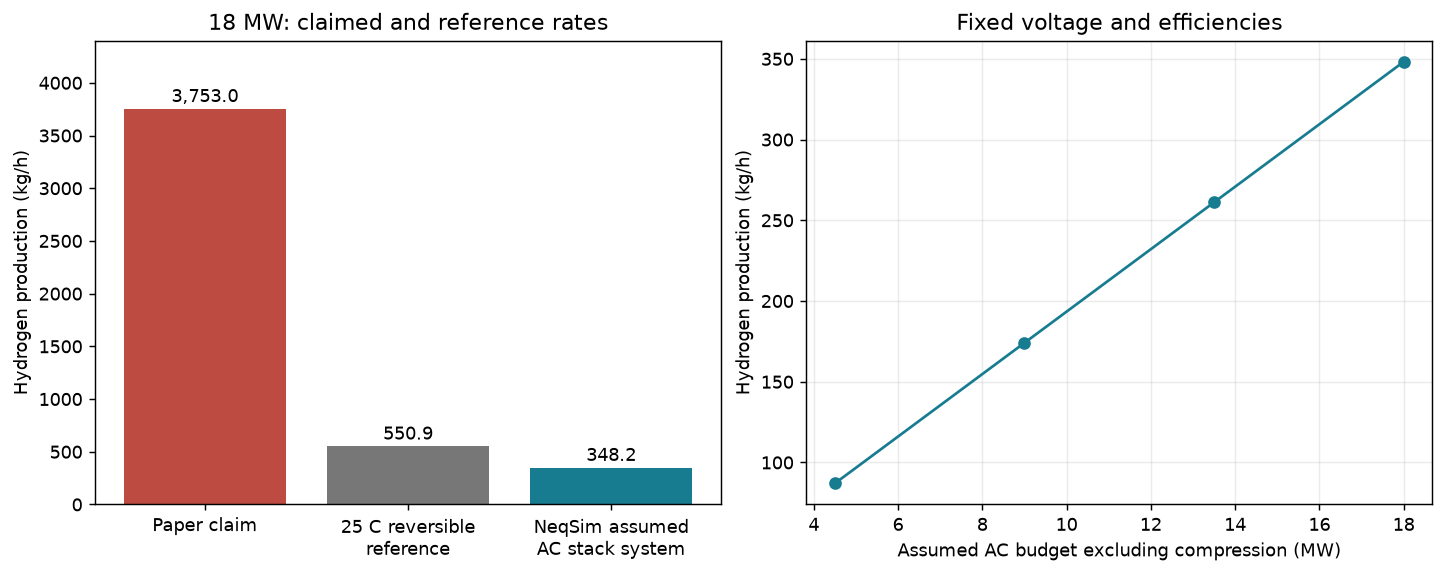

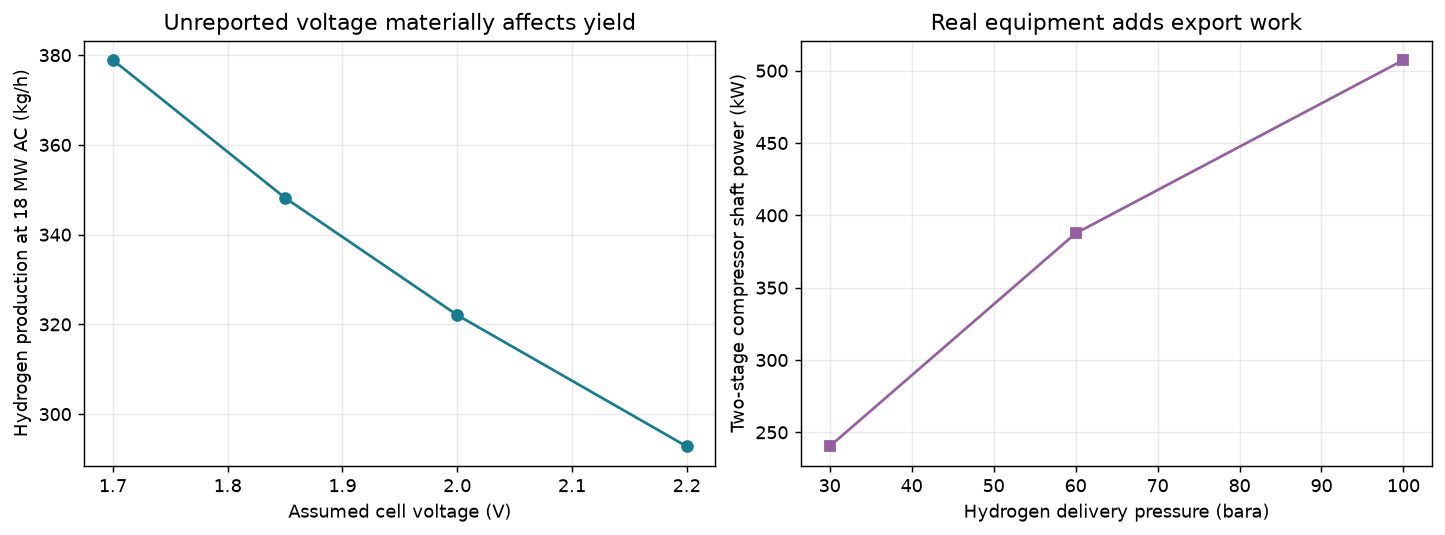

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
labels = ['Paper claim', '25 C reversible\nreference', 'NeqSim assumed\nAC stack system']
rates = [paper['hydrogen_kg_h'], 18000.0 / reversible_sec, base_results['H2 kg/h']]
axes[0].bar(labels, rates, color=['#bd4b41', '#777777', '#187c91'])
axes[0].set_ylabel('Hydrogen production (kg/h)')
axes[0].set_title('18 MW: claimed and reference rates')
for index, rate in enumerate(rates):
    axes[0].text(index, rate + 65, f'{rate:,.1f}', ha='center')
axes[0].set_ylim(0, 4400)
axes[1].plot(loads['AC MW'], loads['H2 kg/h'], 'o-', color='#187c91')
axes[1].set_xlabel('Assumed AC budget excluding compression (MW)')
axes[1].set_ylabel('Hydrogen production (kg/h)')
axes[1].set_title('Fixed voltage and efficiencies')
axes[1].grid(alpha=0.25)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), constrained_layout=True)
axes[0].plot(voltages['Cell V'], voltages['H2 kg/h'], 'o-', color='#187c91')
axes[0].set_xlabel('Assumed cell voltage (V)')
axes[0].set_ylabel('Hydrogen production at 18 MW AC (kg/h)')
axes[0].set_title('Unreported voltage materially affects yield')
axes[1].plot(
    pressures['Delivery bara'], pressures['Compression shaft MW'] * 1000,
    's-', color='#965fa1',
)
axes[1].set_xlabel('Hydrogen delivery pressure (bara)')
axes[1].set_ylabel('Two-stage compressor shaft power (kW)')
axes[1].set_title('Real equipment adds export work')
for axis in axes:
    axis.grid(alpha=0.25)
plt.show()

## 6. Isolated diagnostic: nonunity Faradaic efficiency

This intentionally tests current source behavior **outside the accepted process case**.
With 18 MW DC, 1.85 V and the alkaline default efficiency, compare actual feed water,
reported consumption and products. Also compare POWER and WATER_FEED modes at the same
H₂ production. A consistent current efficiency must affect both modes equally; any
unreacted water needs an explicit outlet or a clearly separate consumption boundary.
The diagnostic is retained as evidence; it is not counted as a passing conservation test.

The [DOE liquid alkaline targets](https://www.energy.gov/cmei/fuels/technical-targets-liquid-alkaline-electrolysis)
distinguish nominal 2022 stack **51 kWh/kg (65% LHV energy efficiency)** from system
**55 kWh/kg (61% LHV)**. Those percentages are not current efficiencies. They provide
context, not validation of this assumed case or a universal Faradaic-efficiency value.

In [9]:
def diagnostic_stack(efficiency=None, water_mol_s=None):
    fluid = SystemSrkEos(STACK_TEMPERATURE_K, STACK_PRESSURE_BARA)
    fluid.addComponent('water', 1.0)
    feed = Stream('diagnostic water', fluid)
    feed.setFlowRate(1.0 if water_mol_s is None else water_mol_s, 'mole/sec')
    feed.run()
    unit = Electrolyzer('isolated diagnostic stack', feed)
    unit.setTechnology(Technology.ALKALINE)
    unit.setCellVoltage(CELL_VOLTAGE)
    if efficiency is not None:
        unit.setFaradaicEfficiency(efficiency)
    if water_mol_s is None:
        unit.sizeStack(18e6)
        unit.setAvailablePower(18e6)
    unit.run()
    return unit, feed

native_default, diagnostic_feed = diagnostic_stack()
default_efficiency = native_default.getFaradaicEfficiency()
diagnostic_h2 = native_default.getHydrogenOutStream().getFlowRate('mole/sec')
water_mode, water_mode_feed = diagnostic_stack(
    efficiency=default_efficiency,
    water_mol_s=diagnostic_h2 / default_efficiency,
)
diagnostic_rows = []
for mode, unit, feed in [
    ('POWER', native_default, diagnostic_feed),
    ('WATER_FEED', water_mode, water_mode_feed),
]:
    produced = unit.getHydrogenOutStream().getFlowRate('mole/sec')
    feed_moles = feed.getFlowRate('mole/sec')
    diagnostic_rows.append([
        mode, unit.getFaradaicEfficiency(), feed_moles, produced,
        unit.getWaterConsumption('mole/sec'),
        100 * (1 - produced / feed_moles),
        unit.getSpecificEnergyConsumption_kWh_per_kg_H2(),
        unit.getMassBalance('kg/sec'),
    ])
diagnostic = pd.DataFrame(diagnostic_rows, columns=[
    'Mode', 'eta F', 'Feed mol/s', 'H2 mol/s', 'Consumption mol/s',
    'Unaccounted water %', 'Native DC SEC', 'Mass residual kg/s',
])
display(diagnostic.round(5))
print('Diagnostic status: current-source defect retained; excluded from valid study results.')
print('Default eta F is', default_efficiency, '; energy efficiency and charge efficiency differ.')
print('Native SEC uses 0.002016 kg/mol; audit references use NIST 0.00201588 kg/mol.')
technology_rows = []
for technology in Technology.values():
    voltage = technology.getDefaultCellVoltage()
    efficiency = technology.getDefaultFaradaicEfficiency()
    expected_sec = 2 * FARADAY * voltage / (efficiency * 0.002016 * 3.6e6)
    technology_rows.append([str(technology), voltage, efficiency, expected_sec])
display(pd.DataFrame(technology_rows, columns=[
    'Technology', 'Default cell V', 'Default eta F', 'Implied DC kWh/kg',
]).round(4))

Diagnostic status: current-source defect retained; excluded from valid study results.
Default eta F is 0.62 ; energy efficiency and charge efficiency differ.
Native SEC uses 0.002016 kg/mol; audit references use NIST 0.00201588 kg/mol.


,Mode,eta F,Feed mol/s,H2 mol/s,Consumption mol/s,Unaccounted water %,Native DC SEC,Mass residual kg/s
0,POWER,0.62,50.42077,31.26088,31.26088,38.0,79.33746,-0.34515
1,WATER_FEED,0.62,50.42077,31.26088,31.26088,38.0,49.18923,-0.34515


,Technology,Default cell V,Default eta F,Implied DC kWh/kg
0,PEM,1.80,0.65,73.6304
1,ALKALINE,1.85,0.62,79.3375
2,SOEC,1.30,0.85,40.6652
3,AEM,1.85,0.60,81.9820


## 7. Engineering conclusion and improvement path

**Suitable now:** a composable steady screening model of power-to-H₂ conversion,
explicit dry-gas cooling/compression, AC/DC accounting, nearby-case sensitivity and
independent Faraday/material checks. `SystemSrkEos` and `ProcessSystem` are relevant;
`PipeBeggsAndBrills` is unnecessary without a specified pipeline. Native electrolyzer
APIs provide more relevant functionality than the issue's generated class suggestions.

**Not established:** the paper's production rate, its 35% KOH circulation and inventory,
wet gas separators/dryers, gas crossover/purity, electrolyte activity and conductivity,
cell polarization, degradation, transient thermal behavior, plant economics or water treatment.
The native stack returns pure dry gases; displayed purity would therefore be an assumption.
Its thermal estimate excludes a full reaction/sensible-enthalpy balance. Native delivery
pressure is a boundary specification; actual compression work is supplied here by equipment.

**Upstream improvements:** [#4681: Faradaic material/mode consistency](https://github.com/equinor/neqsim/issues/4681)
and [#4682: current-efficiency defaults](https://github.com/equinor/neqsim/issues/4682)
contain the executed reproducers and acceptance criteria. The valid
process explicitly uses unity current efficiency. Do not use the diagnostic rates as design outputs.

**Validation level:** analytical electrochemical/electrical checks, stoichiometry,
explicit gas-equipment energy checks and physical trends. No experimental validation and
no independent hydrogen EOS benchmark are claimed. Reproducing the paper requires clarified
power/rate units and boundaries plus cell and electrolyte data; matching its headline rate
by fitting voltage would not be independent validation.

Exercises: replace the assumed voltage with measured polarization data; include rectifier and
pump curves; add a justified wet-product boundary and dryer model; audit total thermal duties
with reaction reference states; add an independently validated hydrogen EOS comparison.

In [10]:
summary = pd.DataFrame([
    ['Reported paper H2', paper['hydrogen_kg_h'], 'kg/h', 'Unqualified source claim'],
    ['NeqSim screening H2', base_results['H2 kg/h'], 'kg/h', 'Explicit assumptions'],
    ['Export electrical SEC', base_results['Export SEC kWh/kg'], 'kWh/kg', 'Includes compression'],
    ['Accepted numerical checks', len(checks), 'checks', 'Diagnostic excluded'],
], columns=['Result', 'Value', 'Unit', 'Interpretation'])
display(summary.round(4))
print('Recommendation: proceed with a qualified NeqSim application study.')
print('First resolve the paper source-data boundary.')
print('Paper-rate reproduction and alkaline-electrolyte validation remain open.')

Recommendation: proceed with a qualified NeqSim application study.
First resolve the paper source-data boundary.
Paper-rate reproduction and alkaline-electrolyte validation remain open.


,Result,Value,Unit,Interpretation
0,Reported paper H2,3753.0000,kg/h,Unqualified source claim
1,NeqSim screening H2,348.2007,kg/h,Explicit assumptions
2,Export electrical SEC,53.2283,kWh/kg,Includes compression
3,Accepted numerical checks,14.0000,checks,Diagnostic excluded
